# Toxicity Classification and Fairness in Online Moderation

## 02 - Logistic Regression

This notebook uses the data prepared in notebook 01 to train several logistic regression models, providing an initial overview of their performance

Objectives:
1. Load the prepared data from notebook 01
2. Convert comments into numerical features using TF-IDF vectorization
3. Train a standard logistic regression classifier
4. Train a second version using balanced class weights to address the approximately 8% toxic distribution
5. Tune hyperparameters and classification threshold
6. Evaluate the final model
7. Save the trained logistic regression model and TF-IDF vectorizer along with their results

### Import necessary packages - load prepared dataset

In [71]:
# imports and load data

from datasets import load_from_disk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

ds = load_from_disk("../data/processed/civil_comments")

# verify correct data preprocesing
print(ds)
print(ds["train"].column_names)
print(ds["train"][0]["text"])
print(ds["train"][0]["label"])

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
        num_rows: 1778797
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
        num_rows: 96255
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
        num_rows: 96862
    })
})
['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label']
This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!
0


#### TF-IDF Vectorization

Here we will convert the comments into numberical features our regression models can use

Term Frequency–Inverse Document Frequency assigns higher importance to words that appear frequently in a particular comment but are relatively uncommon across the dataset. We will create unigram and bigrams, limiting memory usage to reduce training time. The vectorizer is fitted only on the training set to prevent data leakage. The fitted vectorizer is then used to transform the validation set.

In [21]:
# initialize the vectorizer
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=100000,
    dtype="float32"
)

# fit TF-IDF on training comments only
X_train = vectorizer.fit_transform(ds["train"]["text"])
y_train = ds["train"]["label"]

# check the matrix shape
print("Training feature matrix:", X_train.shape)
print("Number of features:", len(vectorizer.vocabulary_))

Training feature matrix: (1778797, 100000)
Number of features: 100000


In [22]:
# transform validation comments using the fitted vectorizer; the matrix is very sparse
X_val = vectorizer.transform(ds["validation"]["text"])
y_val = ds["validation"]["label"]

# prin the shape
print("Validation feature matrix:", X_val.shape)
print("Training and validation features match:",
      X_train.shape[1] == X_val.shape[1])

# inspect some of the learned features
features = vectorizer.get_feature_names_out()
print("Example features:", features[:20])
print("Nonzero features in first comment:", X_train[0].nnz)

# a couple of test cases to make sure vectorization worked properly
assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_train.shape[1] == X_val.shape[1]

print("TF-IDF vectorization verified.")

Validation feature matrix: (96255, 100000)
Training and validation features match: True
Example features: ['00' '00 am' '00 and' '00 for' '00 in' '00 per' '00 pm' '00 to' '000'
 '000 00' '000 000' '000 acres' '000 alaskans' '000 americans' '000 and'
 '000 barrels' '000 but' '000 dollars' '000 each' '000 emails']
Nonzero features in first comment: 32
TF-IDF vectorization verified.


#### Logistic Regression Training

Here we will train two logistic regression classifier models using the TF-IDF features we have just generated:

1. Standard logistic regression, which weights all training examples equally
2. Class-weighted logistic regression, which assigns greater weight to the minority toxic class

Because approximately 8% of the comments are toxic, class weighting may improve recall for toxic comments, potentially at the expense of precision.

In [30]:
# standard logistic regression
lr_standard = LogisticRegression(
    C = 1.0, # regularization strength, which helps control overfitting
    max_iter = 1000, # maximum iterations of optimization allowed to fit the model
    solver = "lbfgs" # common optimization algorithm
)

lr_standard.fit(X_train, y_train)

# class-weighted logistic regression
lr_balanced = LogisticRegression(
    C = 1.0, # regularization strength, which helps control overfitting
    class_weight = "balanced", # changes the training loss impact to account for the imbalance of toxic vs non toxic comments
    max_iter = 1000, # maximum iterations of optimization allowed to fit the model
    solver = "lbfgs" # common optimization algorithm
)

lr_balanced.fit(X_train, y_train)

print("Both logistic regression models trained successfully.")
print("Standard model iterations:", lr_standard.n_iter_[0])
print("Balanced model iterations:", lr_balanced.n_iter_[0])

Both logistic regression models trained successfully.
Standard model iterations: 50
Balanced model iterations: 76


In [34]:
# compare both models on validation data
results = []

for name, model in [("Standard", lr_standard), ("Balanced", lr_balanced)]:
    probs = model.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, preds),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "Recall": recall_score(y_val, preds, zero_division=0),
        "F1": f1_score(y_val, preds, zero_division=0),
        "PR-AUC": average_precision_score(y_val, probs)
    })

pd.DataFrame(results).round(4)

,Model,Accuracy,Precision,Recall,F1,PR-AUC
0,Standard,0.9479,0.7922,0.4599,0.5819,0.7072
1,Balanced,0.9063,0.4488,0.8309,0.5828,0.7067


#### Hyperparameter and Classification Threshold Tuning

Tune the logistic regression model using the validation set, comparing regularization strengths (C = 0.1, 1, 10) and standard versus balanced class weighting. For each configuration, we will select the classification threshold that maximizes validation F1, rather than assuming a threshold of 0.5 is optimal. We will also record precision, recall, and average precision (PR-AUC) to assess performance beyond F1. We will keep the test set untouched throughout this process to avoid data leakage.


In [40]:
# regularization strengths and class weights to compare
C_values = [0.1, 1.0, 10.0]
weight_options = [None, "balanced"]

tuning_results = []
candidate_models = {}

for C in C_values:
    for weight in weight_options:

        # reuse models already trained with C=1
        if C == 1.0 and weight is None:
            model = lr_standard
        elif C == 1.0 and weight == "balanced":
            model = lr_balanced
        else:
            model = LogisticRegression(
                C=C,
                class_weight=weight,
                max_iter=1000,
                solver="lbfgs"
            )
            model.fit(X_train, y_train)

        # predict toxicity probabilities on validation data
        probs = model.predict_proba(X_val)[:, 1]

        # calculate precision and recall at different thresholds
        precision, recall, thresholds = precision_recall_curve(y_val, probs)

        # calculate F1 for each threshold
        f1_values = 2 * precision[:-1] * recall[:-1] / (
            precision[:-1] + recall[:-1] + 1e-12
        )

        best_idx = np.argmax(f1_values)
        best_threshold = thresholds[best_idx]

        # save results for comparison
        tuning_results.append({
            "C": C,
            "Class Weight": str(weight),
            "Threshold": best_threshold,
            "Precision": precision[best_idx],
            "Recall": recall[best_idx],
            "F1": f1_values[best_idx],
            "PR-AUC": average_precision_score(y_val, probs)
        })

        candidate_models[(C, str(weight))] = model

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))

,C,Class Weight,Threshold,Precision,Recall,F1,PR-AUC
0,0.1,None,0.1869,0.6050,0.6016,0.6033,0.6579
1,0.1,balanced,0.6898,0.6039,0.6485,0.6254,0.6812
2,1.0,None,0.2378,0.6440,0.6506,0.6473,0.7072
3,1.0,balanced,0.7859,0.6323,0.6645,0.6480,0.7067
4,10.0,None,0.2619,0.6453,0.6529,0.6491,0.7114
5,10.0,balanced,0.8460,0.6278,0.6709,0.6487,0.7071


In [46]:
# select configuration with highest validation F1
best_row = tuning_df.loc[tuning_df["F1"].idxmax()]

# pull the best model
best_C = best_row["C"]
best_weight = best_row["Class Weight"]
best_threshold = float(best_row["Threshold"])

best_model = candidate_models[(best_C, best_weight)]

# print the best model and hyperparameters
print("Best C:", best_C)
print("Best class weight:", best_weight)
print("Best threshold:", round(best_threshold, 4))
print("Validation F1:", round(best_row["F1"], 4))
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation PR-AUC:", round(best_row["PR-AUC"], 4))

Best C: 10.0
Best class weight: None
Best threshold: 0.2619
Validation F1: 0.6491
Validation precision: 0.6453
Validation recall: 0.6529
Validation PR-AUC: 0.7114


In [50]:
# verify the selected model and threshold
best_probs = best_model.predict_proba(X_val)[:, 1]
best_preds = (best_probs >= best_threshold).astype(int)

# calculate the model's performance metrics
print("Validation accuracy:", round(accuracy_score(y_val, best_preds), 4))
print("Validation precision:", round(precision_score(y_val, best_preds), 4))
print("Validation recall:", round(recall_score(y_val, best_preds), 4))
print("Validation F1:", round(f1_score(y_val, best_preds), 4))

# test cases to make sure everything ran correctly
assert 0 <= best_threshold <= 1
assert best_model is not None

print("Hyperparameter tuning verified.")

Validation accuracy: 0.9444
Validation precision: 0.6453
Validation recall: 0.6529
Validation F1: 0.6491
Hyperparameter tuning verified.


#### Final Model Evaluation

Here we will evaluate the selected logistic regression model on the held-out test set. The model's hyperparameters and classification threshold were selected using validation data, so the test set provides an independent evaluation of performance on unseen comments. We calculate accuracy, precision, recall, F1, average precision (PR-AUC), false-positive rate, and false-negative rate. We also examine the confusion matrix and compare against a majority-class baseline. The model configuration will not be modified based on test results to avoid test leakage.

In [55]:
# transform test comments using the fitted TF-IDF vectorizer
X_test = vectorizer.transform(ds["test"]["text"])
y_test = np.array(ds["test"]["label"])

# predict toxicity probabilities and apply selected threshold using the best model from tuning
test_probs = best_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

print("Test feature matrix:", X_test.shape)
print("Number of predictions:", len(test_preds))

# tests to ensure predictions worked properly
assert X_test.shape[0] == len(y_test)
assert len(test_probs) == len(y_test)
assert np.all((test_probs >= 0) & (test_probs <= 1))

print("Test predictions verified.")

Test feature matrix: (96862, 100000)
Number of predictions: 96862
Test predictions verified.


In [59]:
# calculate confusion matrix values
tn, fp, fn, tp = confusion_matrix(y_test, test_preds, labels=[0, 1]).ravel()

# calculate metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, test_preds),
    "Precision": precision_score(y_test, test_preds, zero_division=0),
    "Recall": recall_score(y_test, test_preds, zero_division=0),
    "F1": f1_score(y_test, test_preds, zero_division=0),
    "PR-AUC": average_precision_score(y_test, test_probs),
    "FPR": fp / (fp + tn),
    "FNR": fn / (fn + tp)
}

print("Final logistic regression test results:")
display(pd.DataFrame([test_metrics]).round(4))

Final logistic regression test results:


,Accuracy,Precision,Recall,F1,PR-AUC,FPR,FNR
0,0.9438,0.6466,0.654,0.6503,0.708,0.031,0.346


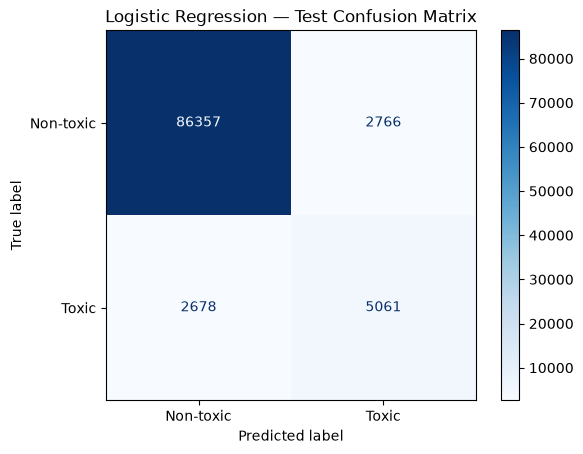

True negatives: 86357
False positives: 2766
False negatives: 2678
True positives: 5061


In [65]:
# display the confusion matrix generated in the previous cell
cm = confusion_matrix(y_test, test_preds, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-toxic", "Toxic"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression — Test Confusion Matrix")
plt.show()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

In [67]:
# finally, since the toxic vs non-toxic comments are imbalanced, we should compare with a model that guessed
# non-toxic every time. That model would obtain an accuracy of 92%, so we want to see that our trained logistic
# model is meaningfully better than that

# model that predicts non-toxic every time
majority_preds = np.zeros(len(y_test), dtype=int)

baseline_comparison = pd.DataFrame([
    {
        "Model": "Majority Class", # non-toxic model
        "Accuracy": accuracy_score(y_test, majority_preds),
        "Precision": precision_score(y_test, majority_preds, zero_division=0),
        "Recall": recall_score(y_test, majority_preds, zero_division=0),
        "F1": f1_score(y_test, majority_preds, zero_division=0)
    },
    {
        "Model": "TF-IDF + Logistic Regression", # our model
        "Accuracy": test_metrics["Accuracy"],
        "Precision": test_metrics["Precision"],
        "Recall": test_metrics["Recall"],
        "F1": test_metrics["F1"]
    }
])

# display the comparison betweeen them
display(baseline_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1
0,Majority Class,0.9201,0.0000,0.000,0.0000
1,TF-IDF + Logistic Regression,0.9438,0.6466,0.654,0.6503


#### Saving Models and Results

Here we will save the selected logistic regression model, fitted TF-IDF vectorizer, classification threshold, test-set predictions, and evaluation metrics. The saved model and vectorizer will be used in our interactive demo. The predictions and metrics will be used in Notebook 04 to compare logistic regression against DistilBERT and conduct demographic fairness and qualitative error analyses.

In [73]:
# save model and vectorizer together (including classification threshold)
joblib.dump(
    (best_model, vectorizer, best_threshold),
    "../models/logistic_regression.joblib"
)

# save test predictions for later analysis
predictions_df = pd.DataFrame({
    "text": ds["test"]["text"],
    "label": y_test,
    "lr_probability": test_probs,
    "lr_prediction": test_preds
})

predictions_df.to_csv("../results/logistic_predictions.csv", index=False)

print("Model and predictions saved.")

Model and predictions saved.
